# 02 — Featurization

Build the modeling dataset, inspect the feature matrix, and explore
feature groups before running full experiments.

In [2]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.modeling.config import load_dataset_config
from src.modeling.dataset import build_modeling_dataset
from src.modeling.features import (
    build_feature_pipeline,
    featurize,
    get_feature_names,
    build_feature_group_index,
)

sns.set_theme(style="whitegrid")

## 1. Load config and build modeling dataset

In [3]:
cfg = load_dataset_config(ROOT / "config/dataset/modeling_dataset_aero_anaero.yaml")
print(cfg.model_dump())

{'curves_file': ['data/processed/aerobic_tidy_curves.csv', 'data/processed/anaerobic_tidy_curves.csv'], 'strain_metadata_file': None, 'output_name': 'aero_anaero_modeling_dataset.csv', 'grain': 'per_well', 'merge': {'left': 'strain_name', 'right': 'strain'}, 'features': {'strain_name': 'OH', 'media_name': 'OH', 'atmosphere': 'OH', 'temperature': 'numeric'}, 'targets': ['growth_class', 'max_od', 'growth_rate']}


In [4]:
df = build_modeling_dataset(cfg, root=ROOT)
df.head()

2026-06-23 16:06:44.235 | INFO     | src.modeling.dataset:build_modeling_dataset:72 - loading curves: [PosixPath('/scratch/chinasse/MicrobeNet/data/processed/aerobic_tidy_curves.csv'), PosixPath('/scratch/chinasse/MicrobeNet/data/processed/anaerobic_tidy_curves.csv')]
2026-06-23 16:06:44.331 | INFO     | src.modeling.dataset:_load_curves:41 - loaded 2 curves files, total shape: 1260 rows x 17 cols
2026-06-23 16:06:44.332 | INFO     | src.modeling.dataset:build_modeling_dataset:128 - keeping per-well granularity (1260 rows)


,exp_id,date,well_id,row,col,well_index,strain_name,media_name,atmosphere,temperature,replicate,max_od,auc,growth_rate,lag_time_h,time_to_max_od_h,growth_class
0,aerobic_a_25,20260325,a_1_0,a,1,0,escherichia coli k12,lb,aerobic,25.0,1,1.374833,81.339258,0.813405,0.235192,30.666667,1
1,aerobic_a_25,20260325,a_2_1,a,2,1,escherichia coli k12,mb,aerobic,25.0,1,0.435893,22.599028,0.610674,0.448222,14.333333,1
2,aerobic_a_25,20260325,a_3_2,a,3,2,escherichia coli k12,nb,aerobic,25.0,1,0.683583,39.182484,0.546716,0.166613,12.333333,1
3,aerobic_a_25,20260325,a_4_3,a,4,3,escherichia coli k12,bhi,aerobic,25.0,1,1.569167,91.604861,0.797525,0.390312,44.000000,1
4,aerobic_a_25,20260325,a_5_4,a,5,4,escherichia coli k12,mrs,aerobic,25.0,1,1.516048,52.588345,0.425336,23.873531,67.000000,1


In [6]:
print(f"Shape: {df.shape}")
print(f"Strains: {df['strain_name'].nunique()}")
print(f"Media: {df['media_name'].unique()}")
print(f"Growth class distribution:\n{df['growth_class'].value_counts()}")

Shape: (1260, 17)
Strains: 27
Media: <ArrowStringArray>
[   'lb',    'mb',    'nb',   'bhi',   'mrs',   'thy',   'tsb',  'gifu',
   'mrc',   'cdm',    'm9', 'water']
Length: 12, dtype: str
Growth class distribution:
growth_class
0    639
1    621
Name: count, dtype: int64


## 2. Build and inspect feature pipeline

In [7]:
# Build (unfitted) transformer
ct, feature_cols, fgm = build_feature_pipeline(cfg, df, root=ROOT)
print(f"Raw feature columns: {feature_cols}")
print(f"Feature group map: {fgm}")

Raw feature columns: ['strain_name', 'media_name', 'atmosphere', 'temperature']
Feature group map: {'strain_name': 'strain', 'media_name': 'media', 'atmosphere': 'condition', 'temperature': 'condition'}


In [8]:
# Fit on all data (EDA only — NOT for CV reporting)
ct.fit(df)
X = ct.transform(df)
feature_names = get_feature_names(ct)

print(f"X shape: {X.shape}")
print(f"Feature names ({len(feature_names)}): {feature_names[:10]} ...")

X shape: (1260, 42)
Feature names (42): ['oh_strain_name__strain_name_acetobacter aceti', 'oh_strain_name__strain_name_acetobacter pasteurianus', 'oh_strain_name__strain_name_acinetobacter baylyi', 'oh_strain_name__strain_name_arthrobacter globiformis', 'oh_strain_name__strain_name_azotobacter vinelandii', 'oh_strain_name__strain_name_bacillus subtilis', 'oh_strain_name__strain_name_bifidobacterium animalis', 'oh_strain_name__strain_name_caulobacter vibrioides', 'oh_strain_name__strain_name_clostridium sporogenes', 'oh_strain_name__strain_name_corynebacterium glutamicum'] ...


In [9]:
# Feature group index (for SHAP grouping)
group_idx = build_feature_group_index(feature_names, fgm)
for group, indices in group_idx.items():
    print(f"{group}: {len(indices)} features (indices {indices[:5]}...)")

strain: 27 features (indices [0, 1, 2, 3, 4]...)
media: 12 features (indices [27, 28, 29, 30, 31]...)
condition: 3 features (indices [39, 40, 41]...)


## 3. Wrapper for notebook exploration

In [10]:
X, y, feat_names, groups, fgm = featurize(df, cfg, target="growth_class", root=ROOT)
print(f"X: {X.shape}, y: {y.shape}, unique groups: {len(np.unique(groups))}")

X: (1260, 42), y: (1260,), unique groups: 27


## 4. Visualize feature matrix

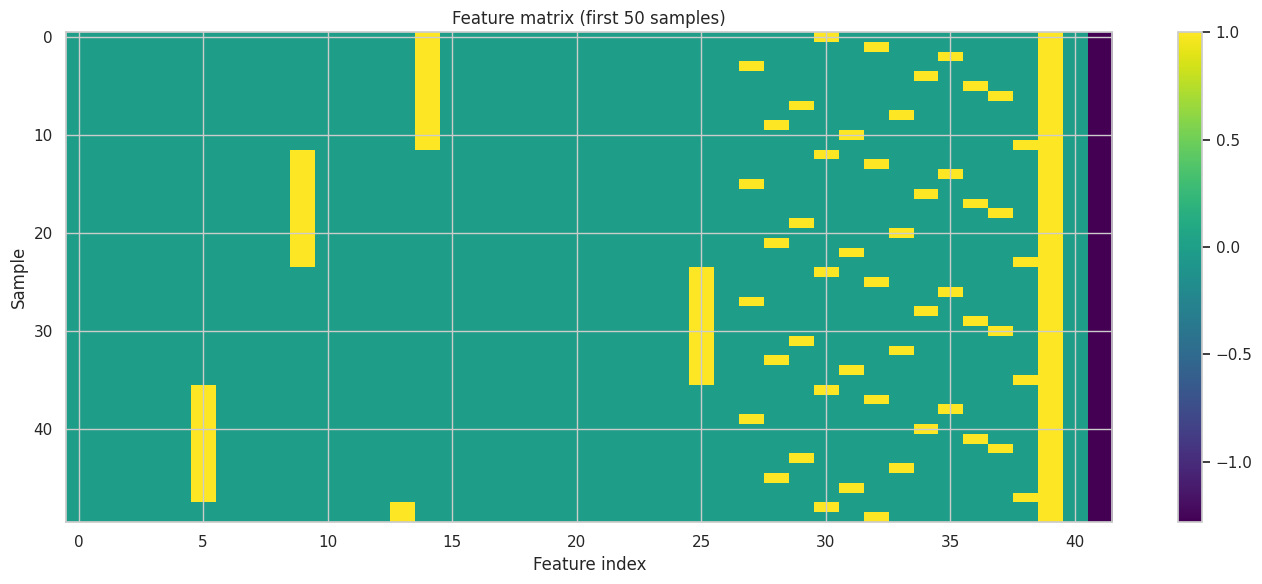

In [11]:
fig, ax = plt.subplots(figsize=(14, 6))
im = ax.imshow(X[:50], aspect="auto", cmap="viridis")
ax.set_xlabel("Feature index")
ax.set_ylabel("Sample")
ax.set_title("Feature matrix (first 50 samples)")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()